# Examen ML Luis Felipe Rodriguez Arce

Saving TicoShop_Clientes.xlsx to TicoShop_Clientes (21).xlsx
 punto 1: exploración de datos 

promedio de características por estado del cliente (0 = se quedó, 1 = se fue):
        recencia  frecuencia  monto_total  antiguedad_meses  quejas  usa_app
se_fue                                                                      
0          37.05        9.95   318,713.82             24.63    0.50     0.50
1         141.62        3.80    85,118.60             28.67    1.14     0.33


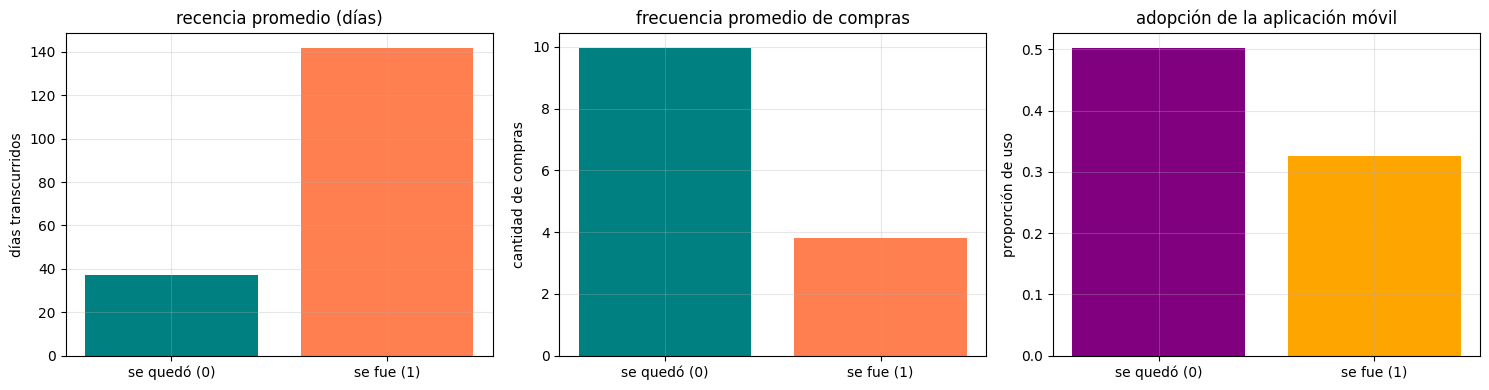


 punto 2: segmentación de clientes 

perfil de los segmentos de clientes:
             total_clientes  tasa_abandono  recencia_promedio  \
segmento                                                        
campeones               502           0.02              11.16   
regulares               503           0.09              43.58   
enfriendose             372           0.16              19.92   
dormidos                623           0.51             135.05   

             frecuencia_promedio  monto_promedio  
segmento                                          
campeones                  18.89      673,164.34  
regulares                   8.83      225,782.31  
enfriendose                 3.90      145,998.66  
dormidos                    3.03       50,037.24  

 punto 3: modelo predictivo de abandono 

comparativa de modelos en datos de prueba:
           regresión logística  árbol de decisión
recall                   53.27              45.79
precisión                76.00            

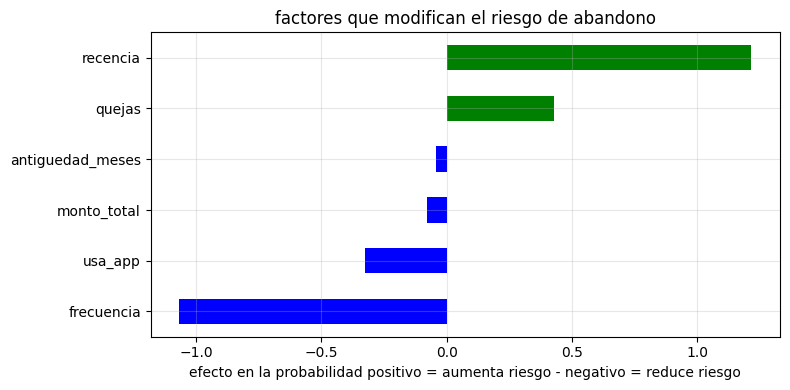


 punto 5: lista de clientes prioritarios 
total de clientes que tienen un riesgo alto 315

top 12 clientes prioritarios para gestión comercial:
     id_cliente   segmento  monto_total  recencia  quejas  usa_app  \
1342      C1343  regulares       165300       155       1        0   
1847      C1848   dormidos       119200       112       2        0   
1578      C1579   dormidos       106100       200       1        0   
1755      C1756   dormidos       105500       365       0        1   
168       C0169   dormidos       103900        75       3        0   
1804      C1805   dormidos       103100       194       1        0   
1001      C1002   dormidos       102900       133       3        0   
843       C0844   dormidos        96700       308       2        1   
1061      C1062   dormidos        93000       135       2        0   
763       C0764   dormidos        91600       140       1        0   
668       C0669   dormidos        89100       112       2        0   
1658      C1659

In [48]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import recall_score, precision_score, confusion_matrix
# definir: escala, tamano, limites, otros
# configuración visual para gráficos, límites de formato y escala
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
# recolectar: variables, formulas de objetivo, consolidacion de datasets
# el codigo carga de archivo
uploaded = files.upload() # Se pide al usuario que suba un archivo.
nombre_archivo = list(uploaded.keys())[0]
# cargar segun el formato de archivo
# Se lee el archivo subido, ya sea CSV o Excel.
if nombre_archivo.endswith('.csv'):
    df = pd.read_csv(nombre_archivo)
else:
    df = pd.read_excel(nombre_archivo, sheet_name=0)
df = df.dropna(axis=1, how="all")  # quita columnas vacias
df.columns = [str(c).strip() for c in df.columns]
# renombrar columnas para estandarizar la estructura del análisis, matching other cells
# Se cambian los nombres de algunas columnas para que sean más fáciles de usar.
df = df.rename(columns={
    "cliente_id": "id_cliente",
    "monto": "monto_total"
})
datos_clientes = df.copy()
# colocar las limitaciones del proyecto de base de datos
Cantidad_de_datos = 300
Semilla = 42
np.random.seed(Semilla)
# pregunta 1 del examen: exploración de datos
print(" punto 1: exploración de datos ")
columnas_analisis = [c for c in ['recencia', 'frecuencia', 'monto_total', 'antiguedad_meses', 'quejas', 'usa_app'] if c in datos_clientes.columns]

# cálculo de promedios para comparar clientes que se quedaron 0 vs los que se fueron 1
# Se calculan los promedios de las características para entender mejor a los clientes que se van y los que se quedan.

resumen_comparativo = datos_clientes.groupby("se_fue")[columnas_analisis].mean()
print("\npromedio de características por estado del cliente (0 = se quedó, 1 = se fue):")
print(resumen_comparativo)

# visualización comparativa de variables clave
# Se crean gráficos para comparar la recencia, frecuencia y uso de la app entre clientes.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# gráfico 1: recencia promedio (días sin comprar)
recencia_mean = datos_clientes.groupby("se_fue")["recencia"].mean()
axes[0].bar(['se quedó (0)', 'se fue (1)'], recencia_mean, color=['teal', 'coral'])
axes[0].set_title("recencia promedio (días)")
axes[0].set_ylabel("días transcurridos")

# gráfico 2: frecuencia promedio de compra
frecuencia_mean = datos_clientes.groupby("se_fue")["frecuencia"].mean()
axes[1].bar(['se quedó (0)', 'se fue (1)'], frecuencia_mean, color=['teal', 'coral'])
axes[1].set_title("frecuencia promedio de compras")
axes[1].set_ylabel("cantidad de compras")

# gráfico 3: adopción de la aplicación móvil
app_mean = datos_clientes.groupby("se_fue")["usa_app"].mean()
axes[2].bar(['se quedó (0)', 'se fue (1)'], app_mean, color=['purple', 'orange'])
axes[2].set_title("adopción de la aplicación móvil")
axes[2].set_ylabel("proporción de uso")
plt.tight_layout()
plt.show()

# pregunta 2 del examen: segmentación de clientes
print("\n punto 2: segmentación de clientes ")

# puntuación rfm mediante cuantiles (recencia, frecuencia, monto)
# Se asignan puntuaciones a los clientes basadas en su recencia, frecuencia y el monto gastado.
datos_clientes['nota_recencia'] = pd.qcut(datos_clientes['recencia'], q=5, labels=[5, 4, 3, 2, 1], duplicates='drop').astype(int)
datos_clientes['nota_frecuencia'] = pd.qcut(datos_clientes['frecuencia'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5]).astype(int)
datos_clientes['nota_monto'] = pd.qcut(datos_clientes['monto_total'], q=5, labels=[1, 2, 3, 4, 5], duplicates='drop').astype(int)
matriz_rfm = datos_clientes[['nota_recencia', 'nota_frecuencia', 'nota_monto']]

# algoritmo k-means para agrupar clientes en 4 segmentos
# Se usa un método para agrupar a los clientes en 4 tipos o segmentos.

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
datos_clientes['cluster'] = kmeans.fit_predict(matriz_rfm)
# asignación de nombres comerciales según la tasa de abandono
# Se dan nombres a los segmentos de clientes según su tendencia a irse.

tasas_abandono = datos_clientes.groupby('cluster')['se_fue'].mean().sort_values()
orden_clusters = tasas_abandono.index
mapa_segmentos = {
    orden_clusters[0]: "campeones",
    orden_clusters[1]: "regulares",
    orden_clusters[2]: "enfriendose",
    orden_clusters[3]: "dormidos"
}
datos_clientes['segmento'] = datos_clientes['cluster'].map(mapa_segmentos)
perfil_segmentos = datos_clientes.groupby('segmento').agg(
    total_clientes=('id_cliente', 'count'),
    tasa_abandono=('se_fue', 'mean'),
    recencia_promedio=('recencia', 'mean'),
    frecuencia_promedio=('frecuencia', 'mean'),
    monto_promedio=('monto_total', 'mean')
).reindex(["campeones", "regulares", "enfriendose", "dormidos"])
print("\nperfil de los segmentos de clientes:")
print(perfil_segmentos)

# pregunta 3 del examen: modelo predictivo

print("\n punto 3: modelo predictivo de abandono ")

# preparar: xy y definirlas
# Se preparan los datos para el modelo, separando lo que usaremos para predecir x y lo que queremos predecir y.
columnas_modelos = [c for c in ['recencia', 'frecuencia', 'monto_total', 'antiguedad_meses', 'quejas', 'usa_app'] if c in datos_clientes.columns]
x = datos_clientes[columnas_modelos]
y = datos_clientes['se_fue']

# dividir: train y test
# Se dividen los datos en dos grupos: uno para que el modelo aprenda (entrenamiento) y otro para probarlo.
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=42, stratify=y)

# escalamiento de variables en conjuntos de entrenamiento y prueba
# Se ajustan los valores de los datos para que todos tengan la misma escala, ayudando al modelo a aprender mejor.
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

# entrenar: modelo
# se usan los datos de entrenamiento para que los modelos de Regresión logistica y arbol de Decision aprendan.
modelo_logistico = LogisticRegression(max_iter=1000, random_state=42)
modelo_logistico.fit(x_train_scaled, y_train)
modelo_arbol = DecisionTreeClassifier(max_depth=4, random_state=42)
modelo_arbol.fit(x_train, y_train)

# prediccion: resultados iniciales para evaluacion
# Se usan los modelos ya entrenados para predecir si los clientes de prueba se iran o no.
pred_log = modelo_logistico.predict(x_test_scaled)
pred_arbol = modelo_arbol.predict(x_test)

# evaluar: metricas a evaluar
# Se revisa qué tan bien funcionaron los modelos usando medidas como el recall y la precisión.
evaluacion = pd.DataFrame({
    'regresión logística': [recall_score(y_test, pred_log) * 100, precision_score(y_test, pred_log) * 100],
    'árbol de decisión': [recall_score(y_test, pred_arbol) * 100, precision_score(y_test, pred_arbol) * 100]
}, index=['recall', 'precisión'])
print("\ncomparativa de modelos en datos de prueba:")
print(evaluacion)

# pregunta 4 del examen: factores de riesgo
print("\n punto 4: factores de riesgo ")
coeficientes = pd.Series(modelo_logistico.coef_[0], index=columnas_modelos)
print("\nimpacto de cada variable en el riesgo de abandono:")
print(coeficientes.sort_values(ascending=False))
fig, ax = plt.subplots(figsize=(8, 4))
colors = ['Green' if v > 0 else 'blue' for v in coeficientes.sort_values()]
coeficientes.sort_values().plot(kind='barh', color=colors, ax=ax)
ax.set_title("factores que modifican el riesgo de abandono")
ax.set_xlabel("efecto en la probabilidad positivo = aumenta riesgo - negativo = reduce riesgo")
plt.tight_layout()
plt.show()

# pregunta : plan de acción y predicción final
print("\n punto 5: lista de clientes prioritarios ")

# prediccion: resultados finales aplicados a toda la base de clientes
# Se calcula la probabilidad de que cada cliente se vaya usando el mejor modelo.

x_scaled_all = scaler.transform(x)
datos_clientes['probabilidad_abandono'] = modelo_logistico.predict_proba(x_scaled_all)[:, 1]
clientes_prioritarios = datos_clientes[datos_clientes['probabilidad_abandono'] >= 0.50].sort_values(
    by=['monto_total', 'probabilidad_abandono'], ascending=[False, False]
)
cols_resultado = [c for c in ['id_cliente', 'segmento', 'monto_total', 'recencia', 'quejas', 'usa_app', 'probabilidad_abandono'] if c in datos_clientes.columns]
print(f"total de clientes que tienen un riesgo alto {len(clientes_prioritarios)}")
print("\ntop 12 clientes prioritarios para gestión comercial:")
print(clientes_prioritarios[cols_resultado].head(12))


# Plan de Retención Strategica


Este plan es principalmente para cartera de clientes de mayor valor y detener la fuga de ingresos de TicoShop.

Centramos el presupuesto y la capacidad operativa en los clientes que gastas mas en el negocio y tienen alto riesgo de se vayan. La meta es proteger nuestros clioentes aumentando la relacion cliente osea la experiencia del cliente.

Acciones

* Público Prioritario: Contacto directo y personalizado a la lista de clientes con mayor compras en el negocio y que tengan alta probabilidad de abandono, haciendoles promociones exclusivas para ellos

* Quejas: Resolución prioritaria para clientes de alto valor dandoles posibilidad a tener contacto mas directo a los resolucianadores de las problematicas y ademas con compensaciones directas para recuperar la confianza puedes ser cupones o promociones exclusivas.

* Fuga por Inactividad: Descuentos exclusivos en sus productos favoritos y ofertas de reactivación.

Primer paso hacer

Lo primero que se debe hacer contactar el publico prioritario y los primeros ahi que contactar son los primero 12 en la linea de codigo que son de codigo_id C1343,C1848,C1579,C1756,C0169,C1805,C1002,C0844,C1062,C0764,C0669,C1659

Esto nos apoya crear un lazo mas cercano con nuestros clientes. Asi recuperando clientes dormidos, aumentando la fidelidad con nuestro cliente que compran mas y teniendo mas retorno de compra, asi aumentado los ingresos del negocio